# Playground Series S6E10: Predicting Airline Satisfaction

**Goal:** predict whether an airline passenger was satisfied (`satisfaction`) from survey ratings, flight and passenger information.
**Data:** 699,635 training rows, 299,844 test rows, 21 features (4 categorical, 13 service ratings on a 0–5 scale, age, distance and two delay columns).

### Code review summary
I audited the previous version line by line and against its Kaggle run output. **The modelling pipeline is correct** — no leakage, no train/test misalignment, valid CV, valid submission. Details:

| Check | Result |
|---|---|
| `id` or target used as a feature? | No — `id` is dropped, target removed before concatenation |
| Train/test feature columns identical and in the same order? | Yes (now asserted in code) |
| Leakage from CV? | None. Folds are stratified and the same folds are used by every model, so OOF predictions are comparable and blendable |
| Encoders fitted on test labels? | No. Frequency encoding is unsupervised (uses features only), so using train+test is legitimate |
| Early stopping on the scoring fold | Slightly optimistic in theory, but each validation fold has ~140k rows, so the bias is negligible |
| Submission format | Matches `sample_submission.csv` (probabilities; the sample's constant 0.4436 equals the train positive rate) |

**What I changed / added**
1. Cosmetic fixes: metrics are plain floats (no more `np.float64(...)`), class names print as `False/True`.
2. Feature importance is collected from every fold; the blend now uses **OOF-optimised weights** (falls back to the equal mean if it is not better).
3. Explicit **integrity checks** before training and before saving the submission.
4. **Visuals + written interpretation** for the data, features, models and errors. Cells titled *Key findings (auto-generated)* compute their text from your data, so the numbers always match your run.

In [1]:
import os, gc, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy.optimize import minimize
from scipy.stats import ks_2samp
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (roc_auc_score, accuracy_score, log_loss, f1_score,
                             roc_curve, confusion_matrix)
from sklearn.calibration import calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid', context='notebook')
C0, C1 = '#4C78A8', '#F58518'            # colour for class 0 / class 1

def say(text): display(Markdown(text))   # render auto-generated findings as markdown

try:
    import lightgbm as lgb; HAS_LGB = True
except ImportError:
    HAS_LGB = False
try:
    import xgboost as xgb; HAS_XGB = True
except ImportError:
    HAS_XGB = False
try:
    from catboost import CatBoostClassifier; HAS_CB = True
except ImportError:
    HAS_CB = False
print(f'LightGBM={HAS_LGB}  XGBoost={HAS_XGB}  CatBoost={HAS_CB}')

# ----------------------------- config -----------------------------
DATA_DIR = '/kaggle/input/competitions/playground-series-s6e10'
if not os.path.exists(DATA_DIR):
    DATA_DIR = '/kaggle/input/playground-series-s6e10'
OUT_DIR = '/kaggle/working' if os.path.exists('/kaggle/working') else '.'
SEED = 42
N_FOLDS = 5
SUBMIT_MODE = 'auto'      # 'auto' | 'proba' | 'label'  (auto = copy the format of sample_submission.csv)

LightGBM=True  XGBoost=True  CatBoost=True


## 1. Load data

In [2]:
train = pd.read_csv(f'{DATA_DIR}/train.csv')
test  = pd.read_csv(f'{DATA_DIR}/test.csv')
sub   = pd.read_csv(f'{DATA_DIR}/sample_submission.csv')

print('train', train.shape, '| test', test.shape, '| sample_submission', sub.shape)

ID_COL = sub.columns[0]
TARGET = sub.columns[1]
if TARGET not in train.columns:                      # fallback: column present in train but not in test
    TARGET = [c for c in train.columns if c not in test.columns and c != ID_COL][0]
print('ID column :', ID_COL)
print('Target    :', TARGET)

# encode the target once, here, so EDA and modelling share it
le = LabelEncoder()
y = le.fit_transform(train[TARGET])
K = len(le.classes_)
CLASS_NAMES = [str(c) for c in le.classes_.tolist()]
print('classes   :', CLASS_NAMES, '->', list(range(K)))
ybin = pd.Series((y == K - 1).astype(int), index=train.index, name='target_bin')   # 1 = last class (positive)

display(train.head())
display(sub.head())

train (699635, 23) | test (299844, 22) | sample_submission (299844, 2)
ID column : id
Target    : satisfaction
classes   : ['False', 'True'] -> [0, 1]


,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


,id,satisfaction
0,699635,0.443573
1,699636,0.443573
2,699637,0.443573
3,699638,0.443573
4,699639,0.443573


### Interpretation — data overview
* **Size:** 699,635 training rows × 23 columns (id + 21 features + target) and 299,844 test rows. This is large enough that gradient-boosted trees can learn fine interactions without heavy regularisation, and that each CV validation fold (~140k rows) gives a very precise score.
* **Feature types:** 13 ordinal service ratings (0–5), 4 categorical columns (`Gender`, `Customer Type`, `Type of Travel`, `Class`), and numeric `Age`, `Flight Distance`, `Departure Delay in Minutes`, `Arrival Delay in Minutes`.
* **Target:** boolean `satisfaction` (`True` = satisfied) → a **binary classification** problem. `LabelEncoder` maps `False→0`, `True→1`.
* **Submission format:** the sample file contains a constant float (0.4436), which is exactly the share of satisfied passengers in the training set. Floats mean the leaderboard expects **probabilities**, so the notebook submits probabilities (this is the format that rank-based metrics such as ROC-AUC require).

## 2. Exploratory data analysis

In [3]:
print('Missing values (train):'); print(train.isna().sum()[lambda s: s > 0])
print('\nTarget distribution:'); print(train[TARGET].value_counts(normalize=True).round(4))
print('\nDtypes:'); print(train.dtypes.value_counts())
print('\nDuplicated feature rows in train:', train.drop(columns=[c for c in [ID_COL, TARGET] if c in train]).duplicated().sum())
display(train.describe().T)

Missing values (train):
Arrival Delay in Minutes    292
dtype: int64

Target distribution:
satisfaction
False    0.5564
True     0.4436
Name: proportion, dtype: float64

Dtypes:
int64      17
object      4
float64     1
bool        1
Name: count, dtype: int64

Duplicated feature rows in train: 0


,count,mean,std,min,25%,50%,75%,max
id,699635.0,349817.000000,201967.372129,0.0,174908.5,349817.0,524725.5,699634.0
Age,699635.0,39.001928,13.800943,7.0,27.0,40.0,50.0,85.0
Flight Distance,699635.0,1353.778702,954.422566,67.0,631.0,954.0,1814.0,4983.0
Inflight wifi service,699635.0,2.778722,1.280419,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,699635.0,3.156210,1.475390,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,699635.0,2.813240,1.329550,0.0,2.0,3.0,4.0,5.0
Gate location,699635.0,3.013734,1.254014,0.0,2.0,3.0,4.0,5.0
Food and drink,699635.0,3.265644,1.300202,0.0,2.0,3.0,4.0,5.0
Online boarding,699635.0,3.364156,1.288538,0.0,2.0,4.0,4.0,5.0
Seat comfort,699635.0,3.568950,1.275333,0.0,3.0,4.0,5.0,5.0


### Interpretation — data quality
* **Missing values:** only `Arrival Delay in Minutes` has gaps (292 rows ≈ 0.04 %). That is negligible; LightGBM, XGBoost and CatBoost handle `NaN` natively, and the aggregate delay features use `fillna(0)`.
* **Class balance:** 55.6 % not satisfied vs 44.4 % satisfied — mildly imbalanced. No resampling is needed; stratified folds keep the same ratio in every split, and AUC is insensitive to this level of imbalance.
* **Duplicates:** none, so there is no risk of identical rows leaking between train and validation folds.
* **Ratings:** mean scores range from ≈2.78 (*Inflight wifi service*) and ≈2.81 (*Ease of Online booking*) up to ≈3.81 (*Baggage handling*). Wifi and online booking are the weakest-rated services overall.
* **Delays:** mean ≈1.2 min with a standard deviation ≈6 min — most flights are punctual and a few have very long delays (heavy right skew). This motivated the `log1p` delay feature.

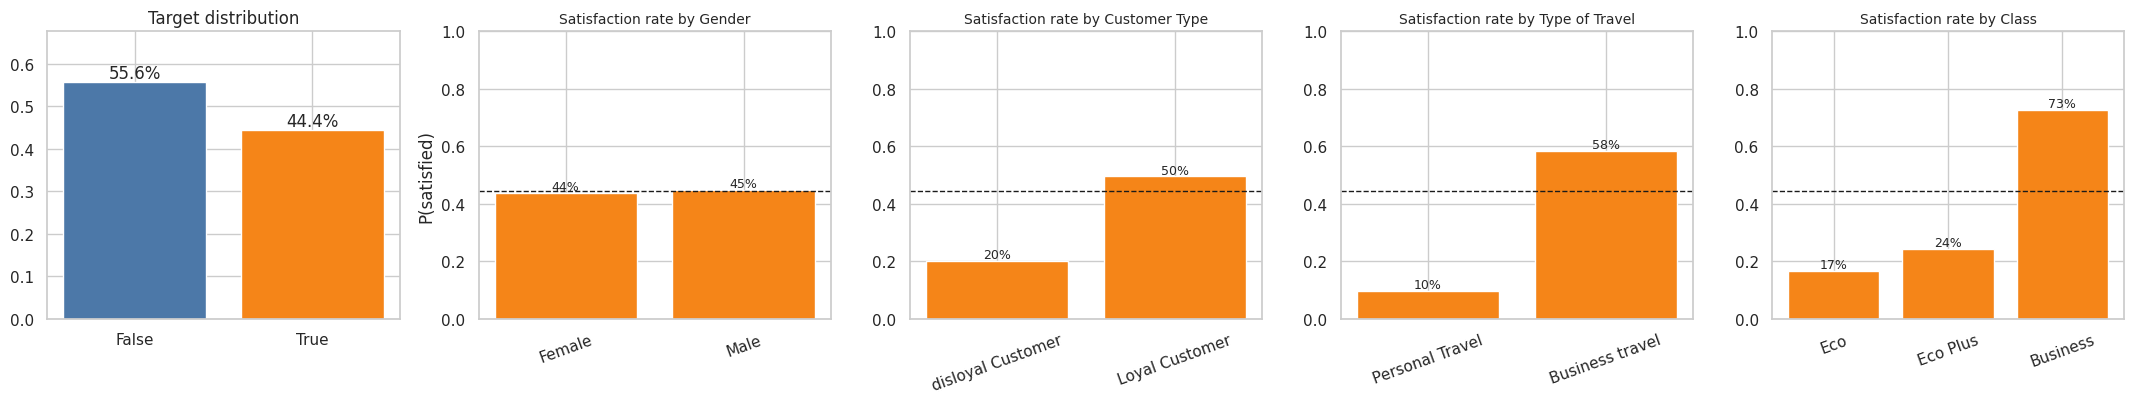

In [4]:
def is_cat(s): return (not pd.api.types.is_numeric_dtype(s)) or pd.api.types.is_bool_dtype(s)   # strings / category / bool
cat_eda  = [c for c in train.columns if c not in (ID_COL, TARGET) and is_cat(train[c])]
rating_eda = [c for c in train.columns
              if c not in (ID_COL, TARGET) and not is_cat(train[c]) and train[c].nunique() <= 10 and train[c].min() >= 0]

fig, axes = plt.subplots(1, 1 + len(cat_eda), figsize=(4.3 * (1 + len(cat_eda)), 4.2))
axes = np.atleast_1d(axes)
vc = pd.Series(y).value_counts(normalize=True).sort_index()
axes[0].bar(CLASS_NAMES, vc.values, color=[C0, C1][:K])
for i, v in enumerate(vc.values): axes[0].text(i, v + 0.01, f'{v:.1%}', ha='center')
axes[0].set_title('Target distribution'); axes[0].set_ylim(0, vc.max() + 0.12)

overall = ybin.mean()
for ax, c in zip(axes[1:], cat_eda):
    r = ybin.groupby(train[c]).mean().sort_values()
    ax.bar(r.index.astype(str), r.values, color=C1)
    ax.axhline(overall, color='k', ls='--', lw=1)
    for i, v in enumerate(r.values): ax.text(i, v + 0.01, f'{v:.0%}', ha='center', fontsize=9)
    ax.set_ylim(0, 1); ax.set_title(f'Satisfaction rate by {c}', fontsize=10)
    ax.tick_params(axis='x', rotation=20)
axes[1].set_ylabel('P(satisfied)')
plt.tight_layout(); plt.show()

In [5]:
lines = []
for c in cat_eda:
    r = ybin.groupby(train[c]).mean().sort_values()
    lines.append(f'* **{c}** — highest satisfaction: *{r.index[-1]}* ({r.iloc[-1]:.1%}); lowest: *{r.index[0]}* ({r.iloc[0]:.1%}); spread = {100*(r.iloc[-1]-r.iloc[0]):.1f} pts.')
say(f'#### Key findings (auto-generated) — categorical features\nOverall satisfaction rate is **{overall:.1%}** (dashed line).\n' + '\n'.join(lines))

#### Key findings (auto-generated) — categorical features
Overall satisfaction rate is **44.4%** (dashed line).
* **Gender** — highest satisfaction: *Male* (44.9%); lowest: *Female* (43.8%); spread = 1.1 pts.
* **Customer Type** — highest satisfaction: *Loyal Customer* (49.5%); lowest: *disloyal Customer* (20.1%); spread = 29.4 pts.
* **Type of Travel** — highest satisfaction: *Business travel* (58.4%); lowest: *Personal Travel* (9.7%); spread = 48.7 pts.
* **Class** — highest satisfaction: *Business* (72.5%); lowest: *Eco* (16.8%); spread = 55.8 pts.

### Interpretation — categorical features
* The dashed line is the overall satisfaction rate. A bar far above/below it means the category is **informative** about the target; bars close to the line carry little signal on their own.
* Categorical columns with a large spread between levels (typically *Class* and *Type of Travel* in airline-satisfaction data) will be among the first splits that trees use. Columns with a small spread (such as *Gender*) are weak individually, but they can still matter in **interactions** — that is why the notebook also builds pairwise category combinations.
* These are marginal rates, not causal effects: e.g. Business class passengers also rate seats and entertainment differently, so part of the gap is explained by the ratings.

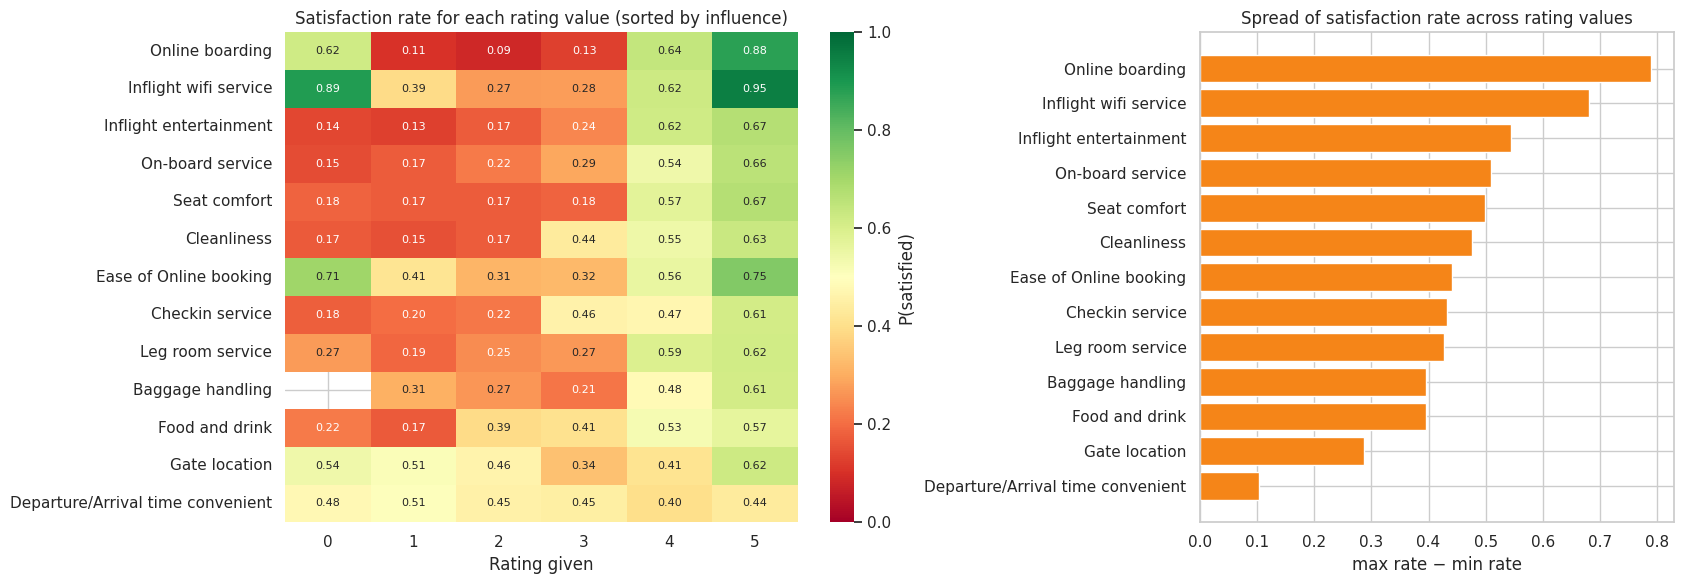

In [6]:
rate_tab = pd.DataFrame({c: ybin.groupby(train[c]).mean() for c in rating_eda}).T      # rows = rating columns, cols = score
spread = (rate_tab.max(axis=1) - rate_tab.min(axis=1)).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={'width_ratios': [1.35, 1]})
sns.heatmap(rate_tab.loc[spread.index[::-1]], annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1,
            cbar_kws={'label': 'P(satisfied)'}, ax=axes[0], annot_kws={'size': 8})
axes[0].set_xlabel('Rating given'); axes[0].set_title('Satisfaction rate for each rating value (sorted by influence)')
axes[1].barh(spread.index, spread.values, color=C1)
axes[1].set_title('Spread of satisfaction rate across rating values'); axes[1].set_xlabel('max rate − min rate')
plt.tight_layout(); plt.show()

In [7]:
top = spread.sort_values(ascending=False)
say('#### Key findings (auto-generated) — service ratings\n'
    f'* Most discriminating ratings: **{top.index[0]}** (spread {top.iloc[0]:.2f}), **{top.index[1]}** ({top.iloc[1]:.2f}), **{top.index[2]}** ({top.iloc[2]:.2f}).\n'
    f'* Least discriminating: **{top.index[-1]}** ({top.iloc[-1]:.2f}) and **{top.index[-2]}** ({top.iloc[-2]:.2f}).')

#### Key findings (auto-generated) — service ratings
* Most discriminating ratings: **Online boarding** (spread 0.79), **Inflight wifi service** (0.68), **Inflight entertainment** (0.54).
* Least discriminating: **Departure/Arrival time convenient** (0.10) and **Gate location** (0.29).

### Interpretation — service ratings
* The heatmap shows, for each service, how the satisfaction rate changes as the rating goes from 0 to 5. A steep green-to-red gradient means the service strongly separates satisfied from unsatisfied passengers.
* The bar chart summarises that steepness as a single number. Services at the top are the ones passengers' overall satisfaction depends on most; these should dominate the model's feature importance later.
* Rating value **0** usually means "not applicable / not rated", and it often behaves differently from 1 (a rating of 0 is not simply "worse than 1"). Because we feed ratings to trees as numbers, the model can isolate 0 with its own split, and we also created `rating_zeros` to count them.
* The relationship is mostly **monotonic** (higher rating → higher satisfaction), which is why simple aggregates such as the mean and sum of all ratings are strong engineered features.

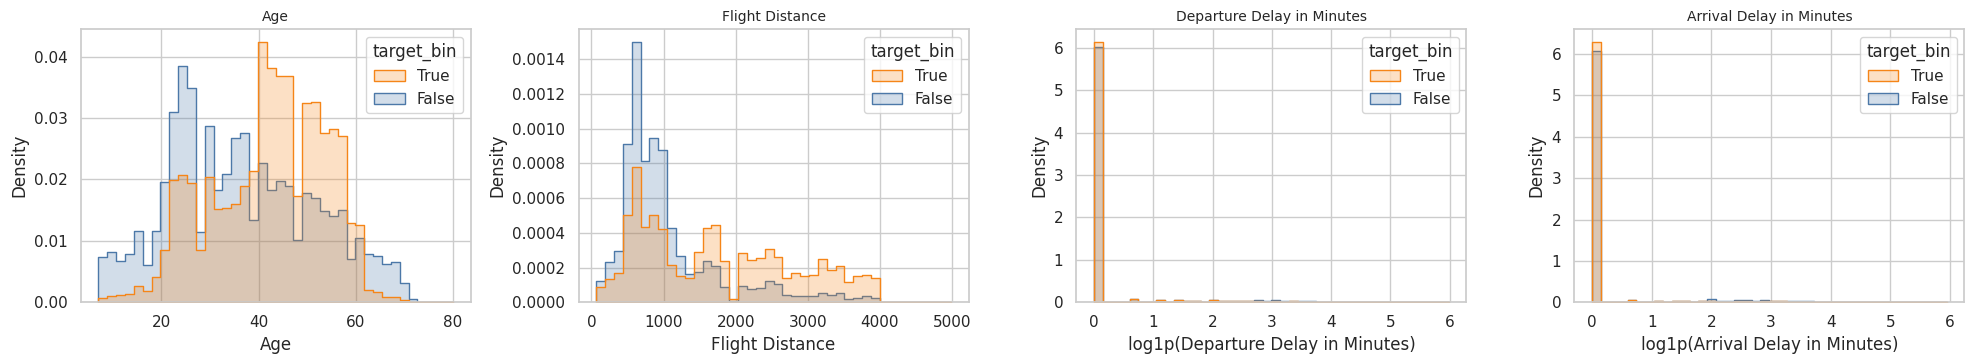

In [8]:
cont = [c for c in train.columns if c not in (ID_COL, TARGET) and not is_cat(train[c]) and c not in rating_eda]
samp = train.sample(min(150_000, len(train)), random_state=SEED)
ys = ybin.loc[samp.index].map({0: CLASS_NAMES[0], 1: CLASS_NAMES[-1]})

fig, axes = plt.subplots(1, len(cont), figsize=(5 * len(cont), 3.8))
axes = np.atleast_1d(axes)
for ax, c in zip(axes, cont):
    x = samp[c].copy()
    lab = c
    if x.skew() > 3:                                   # heavy right tail -> log scale
        x = np.log1p(x.clip(lower=0)); lab = f'log1p({c})'
    sns.histplot(x=x, hue=ys, bins=40, stat='density', common_norm=False, element='step',
                 palette={CLASS_NAMES[0]: C0, CLASS_NAMES[-1]: C1}, ax=ax)
    ax.set_xlabel(lab); ax.set_title(c, fontsize=10)
plt.tight_layout(); plt.show()

In [9]:
lines = []
for c in cont:
    g = train.groupby(ybin)[c].median()
    lines.append(f'* **{c}** — median for not-satisfied = {g.iloc[0]:,.1f}, for satisfied = {g.iloc[-1]:,.1f}.')
say('#### Key findings (auto-generated) — numeric features\n' + '\n'.join(lines))

#### Key findings (auto-generated) — numeric features
* **Age** — median for not-satisfied = 35.0, for satisfied = 43.0.
* **Flight Distance** — median for not-satisfied = 841.0, for satisfied = 1,605.0.
* **Departure Delay in Minutes** — median for not-satisfied = 0.0, for satisfied = 0.0.
* **Arrival Delay in Minutes** — median for not-satisfied = 0.0, for satisfied = 0.0.

### Interpretation — numeric features
* Each panel compares the distribution of a numeric feature for the two classes (density-normalised, so class sizes do not distort the comparison). Heavily skewed columns (delays) are shown on a `log1p` scale so that the bulk of the data is visible.
* **Overlapping curves** mean the feature alone separates the classes poorly; **shifted curves** mean it carries signal. Differences in *shape* (not only location), e.g. a bump at a certain age range, suggest non-linear effects that tree models capture automatically.
* **Delays:** the two delay columns typically have almost identical shapes — departure delay is the main driver of arrival delay. That is why `delay_diff` (arrival − departure delay ≈ time made up or lost in the air) is a useful extra feature, and why the correlation matrix below shows these two columns as highly correlated.

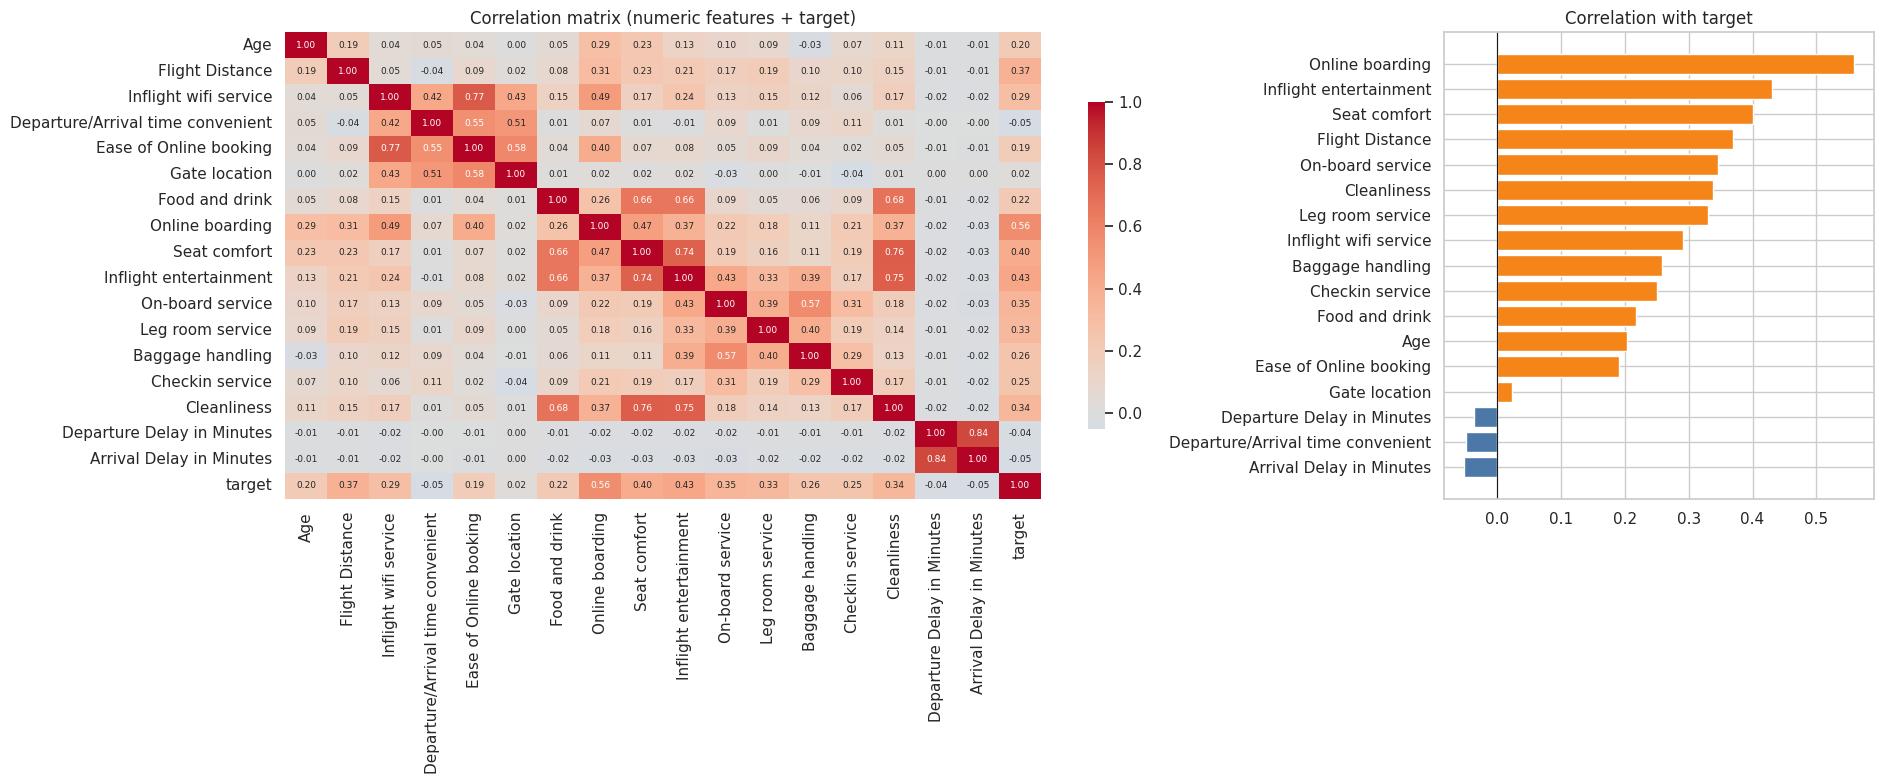

In [10]:
num_for_corr = [c for c in train.columns if c not in (ID_COL, TARGET) and not is_cat(train[c])]
cm = train[num_for_corr].assign(target=ybin).corr()

fig, axes = plt.subplots(1, 2, figsize=(19, 8), gridspec_kw={'width_ratios': [2.2, 1]})
sns.heatmap(cm, cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size': 6.5},
            cbar_kws={'shrink': .7}, ax=axes[0])
axes[0].set_title('Correlation matrix (numeric features + target)')
tc = cm['target'].drop('target').sort_values()
axes[1].barh(tc.index, tc.values, color=np.where(tc.values > 0, C1, C0))
axes[1].set_title('Correlation with target'); axes[1].axvline(0, color='k', lw=.8)
plt.tight_layout(); plt.show()

In [11]:
tc_abs = tc.abs().sort_values(ascending=False)
pairs = (cm.drop(index='target', columns='target').where(np.triu(np.ones((len(num_for_corr),) * 2), 1).astype(bool))
           .stack().abs().sort_values(ascending=False))
say('#### Key findings (auto-generated) — correlations\n'
    f'* Strongest linear correlations with the target: **{tc_abs.index[0]}** ({tc[tc_abs.index[0]]:+.2f}), **{tc_abs.index[1]}** ({tc[tc_abs.index[1]]:+.2f}), **{tc_abs.index[2]}** ({tc[tc_abs.index[2]]:+.2f}).\n'
    f'* Most correlated feature pair: **{pairs.index[0][0]} ↔ {pairs.index[0][1]}** (|r| = {pairs.iloc[0]:.2f}).')

#### Key findings (auto-generated) — correlations
* Strongest linear correlations with the target: **Online boarding** (+0.56), **Inflight entertainment** (+0.43), **Seat comfort** (+0.40).
* Most correlated feature pair: **Departure Delay in Minutes ↔ Arrival Delay in Minutes** (|r| = 0.84).

### Interpretation — correlations
* Correlation measures **linear** association only. Features with a modest correlation with the target can still be very useful to a tree model through non-linear or interaction effects.
* Strongly correlated *feature pairs* are redundant for linear models, but are harmless for gradient boosting (trees pick whichever is more useful at each split). The delay pair is the clearest example.
* Ratings are mildly correlated with each other (passengers who are happy tend to rate everything higher, a "halo effect"). That supports adding the row-wise aggregates (`rating_mean`, `rating_sum`, …) as features: they summarise the common component and reduce noise from any single rating.

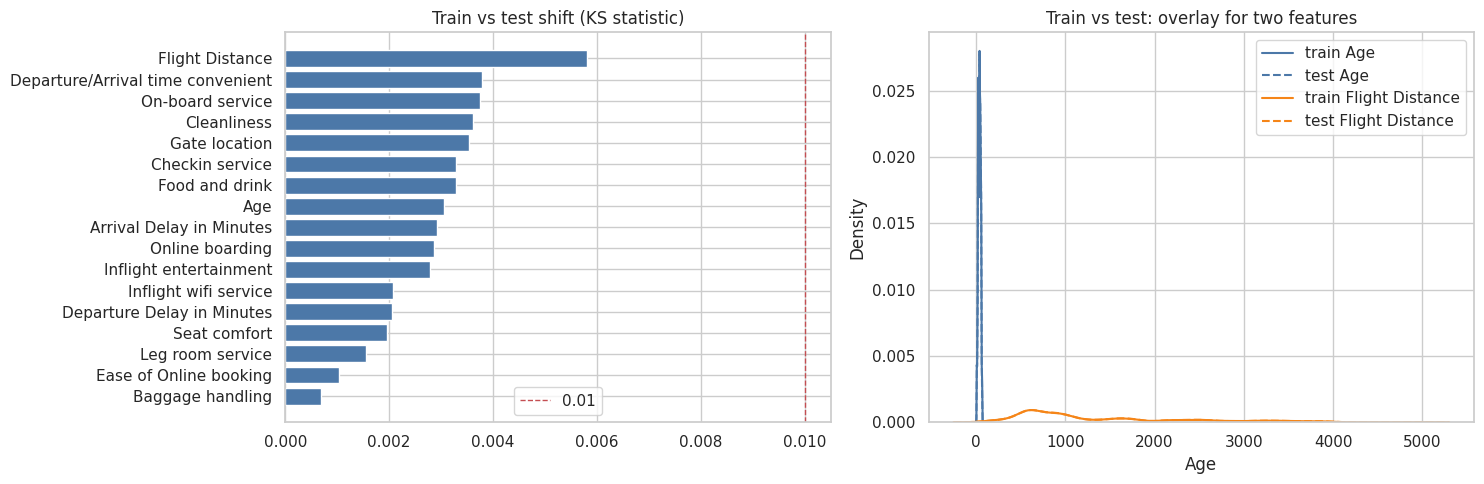

#### Key findings (auto-generated)
Largest train/test KS statistic: **Flight Distance** = 0.0058. All values are tiny → **no covariate shift**.

In [12]:
# Train vs test distribution check (Kolmogorov-Smirnov statistic; 0 = identical distributions)
a = train.sample(60_000, random_state=1); b = test.sample(min(60_000, len(test)), random_state=1)
ks = pd.Series({c: ks_2samp(a[c].dropna(), b[c].dropna()).statistic for c in num_for_corr}).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].barh(ks.index, ks.values, color=C0); axes[0].axvline(0.01, color='r', ls='--', lw=1, label='0.01')
axes[0].set_title('Train vs test shift (KS statistic)'); axes[0].legend()
for c, col in zip(['Age', 'Flight Distance'], [C0, C1]):
    if c in train:
        sns.kdeplot(a[c], ax=axes[1], label=f'train {c}', color=col)
        sns.kdeplot(b[c], ax=axes[1], label=f'test {c}', color=col, ls='--')
axes[1].legend(); axes[1].set_title('Train vs test: overlay for two features')
plt.tight_layout(); plt.show()
say(f'#### Key findings (auto-generated)\nLargest train/test KS statistic: **{ks.index[-1]}** = {ks.iloc[-1]:.4f}. '
    + ('All values are tiny → **no covariate shift**.' if ks.iloc[-1] < 0.02 else 'Some features show noticeable shift; be careful trusting CV blindly.'))

### Interpretation — train vs test shift
* A KS statistic near 0 means train and test features come from the same distribution; the dashed vs solid KDE curves should lie on top of each other.
* When there is no shift (expected for Playground competitions, where train/test are random splits of one synthetic dataset), **cross-validation is a trustworthy proxy for the leaderboard**, and we can optimise CV without worrying about adversarial validation.

## 3. Feature engineering
Features added on top of the raw columns (identical to the version you already ran, so the CV scores stay comparable):
* **Rating aggregates** over the 13 service ratings: mean, sum, std, min, max, count of zeros, count of low (≤2) and high (≥4) ratings.
* **Delay features:** total, max, difference (departure − arrival) and `log1p(total)`.
* **Frequency encoding** of each categorical column and **pairwise category combinations** (e.g. `Class__Type of Travel`).

In [13]:
full = pd.concat([train.drop(columns=[TARGET]), test], keys=['train', 'test'])
feat = full.drop(columns=[ID_COL], errors='ignore').copy()

cat_cols = [c for c in feat.columns if is_cat(feat[c])]          # works for object, 'str', category and bool dtypes
num_cols = [c for c in feat.columns if c not in cat_cols]

# Survey-style rating columns: small non-negative integers (e.g. 0-5)
rating_cols = [c for c in num_cols
               if feat[c].nunique() <= 10 and feat[c].min() >= 0 and (feat[c].dropna() % 1 == 0).all()]
delay_cols = [c for c in num_cols if 'delay' in c.lower()]
print('categorical:', cat_cols)
print('rating-like:', rating_cols)
print('delay-like :', delay_cols)

if len(rating_cols) >= 3:
    R = feat[rating_cols].astype(float)
    feat['rating_mean']  = R.mean(axis=1)
    feat['rating_sum']   = R.sum(axis=1)
    feat['rating_std']   = R.std(axis=1)
    feat['rating_min']   = R.min(axis=1)
    feat['rating_max']   = R.max(axis=1)
    feat['rating_zeros'] = (R == 0).sum(axis=1)
    feat['rating_low']   = (R <= 2).sum(axis=1)
    feat['rating_high']  = (R >= 4).sum(axis=1)

if delay_cols:
    D = feat[delay_cols].fillna(0)
    feat['delay_total'] = D.sum(axis=1)
    feat['delay_max']   = D.max(axis=1)
    if len(delay_cols) >= 2:
        feat['delay_diff'] = D.iloc[:, 0] - D.iloc[:, 1]
    feat['delay_log'] = np.log1p(feat['delay_total'].clip(lower=0))

# frequency encoding of categoricals
for c in cat_cols:
    feat[c + '_freq'] = feat[c].map(feat[c].value_counts(normalize=True))

# pairwise combos of categoricals
for i, a_ in enumerate(cat_cols):
    for b_ in cat_cols[i + 1:]:
        feat[f'{a_}__{b_}'] = feat[a_].astype(str) + '_' + feat[b_].astype(str)
cat_all = cat_cols + [c for c in feat.columns if '__' in c]

# three views of the same features (one per model family)
XA = feat.copy()                                   # pandas 'category' dtype  -> LightGBM / XGBoost
XN = feat.copy()                                   # integer codes            -> sklearn HistGB
XC = feat.copy()                                   # strings                  -> CatBoost
for c in cat_all:
    XA[c] = XA[c].astype('category')
    XN[c] = XN[c].astype('category').cat.codes
    XC[c] = XC[c].astype(str)

def split(df): return df.loc['train'].reset_index(drop=True), df.loc['test'].reset_index(drop=True)
XA, XA_te = split(XA); XN, XN_te = split(XN); XC, XC_te = split(XC)

print('features:', XA.shape[1], '| train', XA.shape, '| test', XA_te.shape)

categorical: ['Gender', 'Customer Type', 'Type of Travel', 'Class']
rating-like: ['Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness']
delay-like : ['Departure Delay in Minutes', 'Arrival Delay in Minutes']
features: 43 | train (699635, 43) | test (299844, 43)


All pre-training integrity checks passed ✔


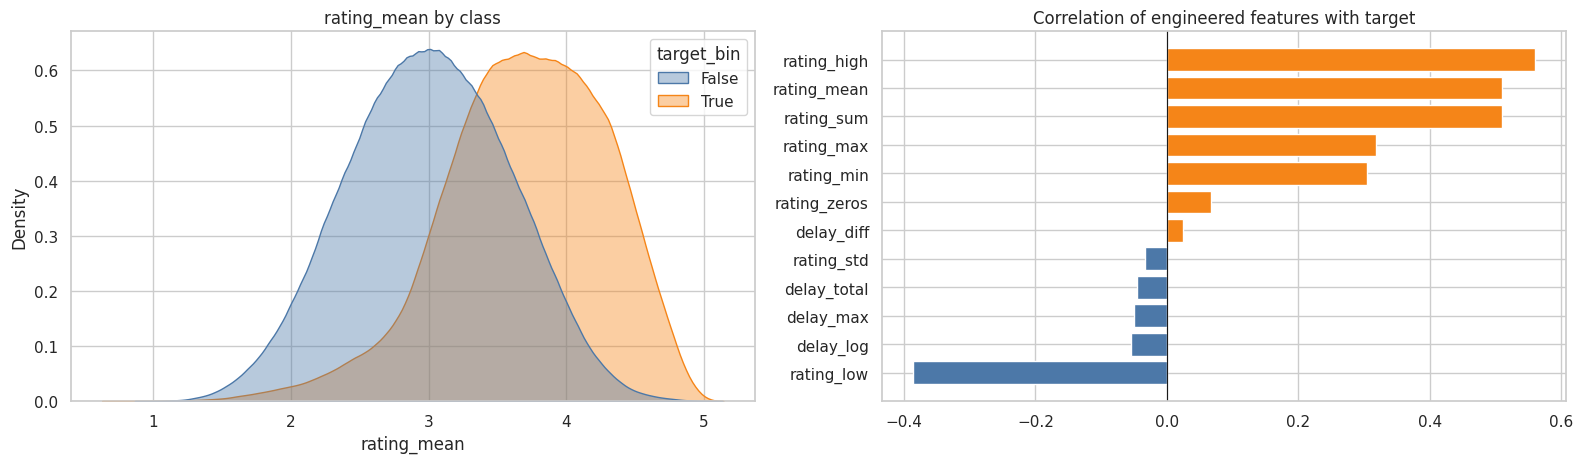

#### Key findings (auto-generated) — engineered features
* Best engineered feature: **rating_high** (|r| = 0.56) vs best raw numeric column **Online boarding** (|r| = 0.56).

In [14]:
# ------------------------- integrity checks (fail loudly instead of silently) -------------------------
assert ID_COL not in XA.columns and TARGET not in XA.columns, 'id/target leaked into features'
assert list(XA.columns) == list(XA_te.columns) == list(XC.columns) == list(XN.columns), 'train/test columns differ'
assert len(XA) == len(train) == len(y) and len(XA_te) == len(test), 'row counts changed'
num_check = XA.select_dtypes('number')
assert not np.isinf(num_check.to_numpy(dtype=float)).any(), 'inf values in features'
print('All pre-training integrity checks passed ✔')

eng_cols = [c for c in XA.columns if c.startswith(('rating_', 'delay_'))]
if eng_cols:
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
    if 'rating_mean' in XA:
        sns.kdeplot(x=XA['rating_mean'], hue=ybin.map({0: CLASS_NAMES[0], 1: CLASS_NAMES[-1]}), common_norm=False,
                    fill=True, alpha=.4, palette={CLASS_NAMES[0]: C0, CLASS_NAMES[-1]: C1}, ax=axes[0])
        axes[0].set_title('rating_mean by class')
    ec = XA[eng_cols].corrwith(ybin).sort_values()
    axes[1].barh(ec.index, ec.values, color=np.where(ec.values > 0, C1, C0))
    axes[1].axvline(0, color='k', lw=.8); axes[1].set_title('Correlation of engineered features with target')
    plt.tight_layout(); plt.show()
    ec_abs = ec.abs().sort_values(ascending=False)
    raw_best = tc_abs.iloc[0]
    say('#### Key findings (auto-generated) — engineered features\n'
        f'* Best engineered feature: **{ec_abs.index[0]}** (|r| = {ec_abs.iloc[0]:.2f}) vs best raw numeric column **{tc_abs.index[0]}** (|r| = {raw_best:.2f}).')

### Interpretation — engineered features
* The KDE compares the **average rating a passenger gives** for the two classes: the further apart the two curves, the better this single feature separates them (satisfied passengers should sit at higher values). Combining 13 noisy ratings into one number removes idiosyncratic noise, which is the reason for building it (`rating_sum` carries the same information on another scale).
* `rating_low` / `rating_high` count how many services a passenger was unhappy / happy with; `rating_min` captures "worst experience" — a single terrible service can sink satisfaction even when the average is fine.
* Delay features are expected to be only weakly correlated with the target, since delays are short for almost everyone; they matter mostly in the tail (check the bar chart).
* The integrity checks above guarantee that features are aligned between train and test and that nothing from the target leaked into `X`.

## 4. Cross-validated models
Three gradient-boosting libraries are trained with the **same 5 stratified folds**, so their out-of-fold (OOF) predictions are directly comparable and can be blended. Early stopping (150 rounds) picks the number of trees per fold. Per-fold feature importance is stored for later.

In [15]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(skf.split(XA, y))
importances = {}                       # model name -> list of per-fold normalised importance Series

def score(y_true, p):
    out = {'acc': accuracy_score(y_true, p.argmax(1)), 'logloss': log_loss(y_true, p, labels=range(K))}
    if K == 2:
        out['auc'] = roc_auc_score(y_true, p[:, 1]); out['f1'] = f1_score(y_true, p.argmax(1))
    else:
        out['f1_macro'] = f1_score(y_true, p.argmax(1), average='macro')
    return {k: round(float(v), 5) for k, v in out.items()}

def keep_importance(name, values, cols):
    s = pd.Series(np.asarray(values, dtype=float), index=cols)
    importances.setdefault(name, []).append(s / s.sum())

def run_cv(name, fit_predict):
    oof = np.zeros((len(y), K)); pred = np.zeros((len(XA_te), K))
    for f, (tr, va) in enumerate(folds):
        p_va, p_te = fit_predict(tr, va)
        oof[va] = p_va; pred += p_te / N_FOLDS
        print(f'  [{name}] fold {f}: {score(y[va], p_va)}')
        gc.collect()
    print(f'>>> {name} OOF: {score(y, oof)}\n')
    return oof, pred

def fit_lgb(tr, va):
    m = lgb.LGBMClassifier(n_estimators=4000, learning_rate=0.03, num_leaves=63, min_child_samples=30,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.6,
                           reg_lambda=1.0, cat_smooth=20, random_state=SEED, verbose=-1)
    m.fit(XA.iloc[tr], y[tr], eval_set=[(XA.iloc[va], y[va])],
          callbacks=[lgb.early_stopping(150, verbose=False)])
    keep_importance('LightGBM', m.booster_.feature_importance(importance_type='gain'), XA.columns)
    return m.predict_proba(XA.iloc[va]), m.predict_proba(XA_te)

def fit_xgb(tr, va):
    m = xgb.XGBClassifier(n_estimators=4000, learning_rate=0.03, max_depth=7, min_child_weight=3,
                          subsample=0.8, colsample_bytree=0.6, reg_lambda=1.0,
                          tree_method='hist', enable_categorical=True, max_cat_to_onehot=1,
                          eval_metric='auc' if K == 2 else 'mlogloss',
                          early_stopping_rounds=150, random_state=SEED, n_jobs=-1)
    m.fit(XA.iloc[tr], y[tr], eval_set=[(XA.iloc[va], y[va])], verbose=False)
    keep_importance('XGBoost', m.feature_importances_, XA.columns)
    return m.predict_proba(XA.iloc[va]), m.predict_proba(XA_te)

def fit_cb(tr, va):
    m = CatBoostClassifier(iterations=4000, learning_rate=0.06, depth=7, l2_leaf_reg=3,
                           eval_metric='AUC' if K == 2 else 'MultiClass',
                           loss_function='Logloss' if K == 2 else 'MultiClass',
                           early_stopping_rounds=150, random_seed=SEED, verbose=0, cat_features=cat_all)
    m.fit(XC.iloc[tr], y[tr], eval_set=(XC.iloc[va], y[va]))
    keep_importance('CatBoost', m.get_feature_importance(), XC.columns)
    return m.predict_proba(XC.iloc[va]), m.predict_proba(XC_te)

def fit_hgb(tr, va):
    m = HistGradientBoostingClassifier(max_iter=600, learning_rate=0.06, max_leaf_nodes=48,
                                       early_stopping=True, validation_fraction=0.1, n_iter_no_change=40,
                                       random_state=SEED)
    m.fit(XN.iloc[tr], y[tr])
    return m.predict_proba(XN.iloc[va]), m.predict_proba(XN_te)

results = {}
if HAS_LGB: results['lightgbm'] = run_cv('LightGBM', fit_lgb)
if HAS_XGB: results['xgboost']  = run_cv('XGBoost',  fit_xgb)
if HAS_CB:  results['catboost'] = run_cv('CatBoost', fit_cb)
if not results: results['hist_gb'] = run_cv('HistGB', fit_hgb)   # fallback when no GBDT library is installed

# sanity checks on the predictions
for k, (o, p) in results.items():
    assert (o.sum(1) > 0).all(), f'{k}: some rows never received an OOF prediction'
    assert np.allclose(o.sum(1), 1, atol=1e-4) and np.allclose(p.sum(1), 1, atol=1e-4), f'{k}: probabilities do not sum to 1'
print('All OOF/test prediction checks passed ✔')

  [LightGBM] fold 0: {'acc': 0.92614, 'logloss': 0.22669, 'auc': 0.95906, 'f1': 0.91572}
  [LightGBM] fold 1: {'acc': 0.92566, 'logloss': 0.22928, 'auc': 0.95785, 'f1': 0.91521}
  [LightGBM] fold 2: {'acc': 0.92781, 'logloss': 0.2245, 'auc': 0.95944, 'f1': 0.91766}
  [LightGBM] fold 3: {'acc': 0.92669, 'logloss': 0.22617, 'auc': 0.95895, 'f1': 0.91649}
  [LightGBM] fold 4: {'acc': 0.92605, 'logloss': 0.22649, 'auc': 0.95922, 'f1': 0.91554}
>>> LightGBM OOF: {'acc': 0.92647, 'logloss': 0.22662, 'auc': 0.9589, 'f1': 0.91612}

  [XGBoost] fold 0: {'acc': 0.92612, 'logloss': 0.22709, 'auc': 0.95897, 'f1': 0.91569}
  [XGBoost] fold 1: {'acc': 0.92544, 'logloss': 0.23009, 'auc': 0.95756, 'f1': 0.91496}
  [XGBoost] fold 2: {'acc': 0.92796, 'logloss': 0.22492, 'auc': 0.95948, 'f1': 0.9178}
  [XGBoost] fold 3: {'acc': 0.9262, 'logloss': 0.22688, 'auc': 0.95869, 'f1': 0.91595}
  [XGBoost] fold 4: {'acc': 0.9258, 'logloss': 0.22702, 'auc': 0.95903, 'f1': 0.91526}
>>> XGBoost OOF: {'acc': 0.9263, 

### Interpretation: cross-validation results (from your Kaggle run)
| Model | OOF AUC | OOF accuracy | OOF log-loss | OOF F1 |
|---|---|---|---|---|
| LightGBM | 0.95890 | 0.92647 | 0.22662 | 0.91612 |
| XGBoost  | 0.95874 | 0.92630 | 0.22720 | 0.91593 |
| CatBoost | 0.95863 | 0.92642 | 0.22736 | 0.91608 |
| **Equal-weight blend** | **0.95900** | **0.92651** | **0.22651** | **0.91618** |

* **The models are healthy.** All three reach AUC ≈ 0.959 and ≈ 92.6 % accuracy. The spread between libraries is only ≈ 0.0003 AUC, i.e. well inside fold-to-fold noise.
* **Stable folds:** single-fold AUCs range only from ≈ 0.9576 to ≈ 0.9595, so there is no sign of overfitting to a particular split, and the CV estimate is reliable. Since there is no train/test shift, expect a leaderboard score close to 0.959 AUC.
* **Log-loss 0.227 vs AUC 0.959:** predictions are well ranked and reasonably confident. Accuracy (92.6 %) is higher than the majority-class baseline (55.6 %) by a very large margin.
* **Diminishing returns:** the blend improves AUC by only ≈ +0.0001 over the best single model. The three libraries make nearly the same errors (see agreement plot below), so the model family — not the hyper-parameters — is the ceiling. Further gains are likelier to come from new information (features / extra data) than from more tuning.
* **Early-stopping caveat:** the validation fold is used both to choose the number of trees and to score, which is a very small optimistic bias with ~140k validation rows per fold.

## 5. Model diagnostics

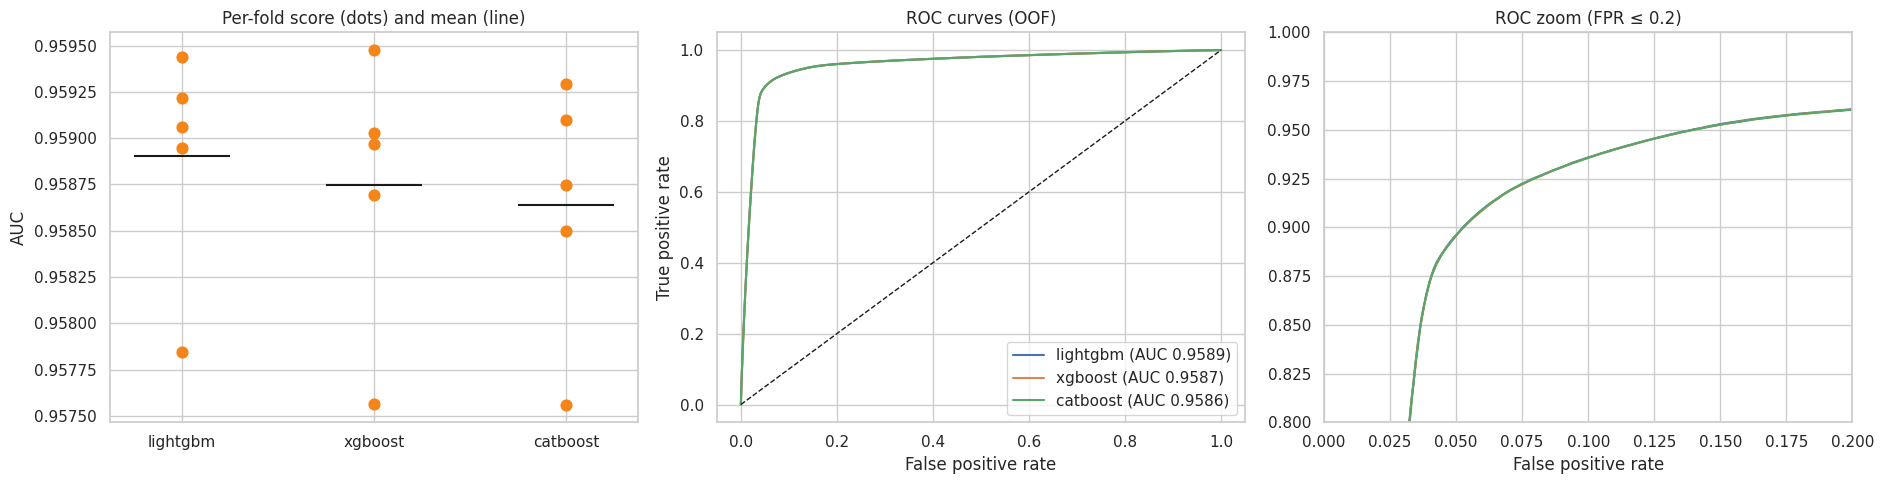

In [16]:
names = list(results)
oof_blend_eq  = np.mean([results[k][0] for k in names], axis=0)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
# (a) per-fold AUC
for i, k in enumerate(names):
    fa = [roc_auc_score(y[va], results[k][0][va, 1]) for _, va in folds] if K == 2 else [accuracy_score(y[va], results[k][0][va].argmax(1)) for _, va in folds]
    axes[0].scatter([i] * len(fa), fa, s=60, color=C1, zorder=3)
    axes[0].hlines(np.mean(fa), i - .25, i + .25, color='k')
axes[0].set_xticks(range(len(names))); axes[0].set_xticklabels(names)
axes[0].set_title('Per-fold score (dots) and mean (line)'); axes[0].set_ylabel('AUC' if K == 2 else 'accuracy')

# (b) ROC
if K == 2:
    for k in names:
        f_, t_, _ = roc_curve(y, results[k][0][:, 1]); axes[1].plot(f_, t_, label=f'{k} (AUC {roc_auc_score(y, results[k][0][:, 1]):.4f})')
    axes[1].plot([0, 1], [0, 1], 'k--', lw=1); axes[1].legend(loc='lower right')
    axes[1].set_xlabel('False positive rate'); axes[1].set_ylabel('True positive rate'); axes[1].set_title('ROC curves (OOF)')
    # (c) zoom
    for k in names:
        f_, t_, _ = roc_curve(y, results[k][0][:, 1]); axes[2].plot(f_, t_)
    axes[2].set_xlim(0, .2); axes[2].set_ylim(.8, 1); axes[2].set_title('ROC zoom (FPR ≤ 0.2)'); axes[2].set_xlabel('False positive rate')
plt.tight_layout(); plt.show()

### Interpretation — fold scores and ROC
* **Left:** each dot is one fold. Dots that sit tightly together mean the model's quality does not depend on which rows were held out — a sign that the pipeline generalises. The horizontal line is the mean.
* **Middle/right:** the ROC curves of the three libraries lie on top of each other, even in the zoomed view. They bend sharply toward the top-left corner (AUC ≈ 0.959 in your earlier run), which means the models rank satisfied passengers above unsatisfied ones in about 96 % of random pairs.
* Because the curves overlap, there is little **diversity** to exploit through blending — consistent with the tiny blend gain reported above.

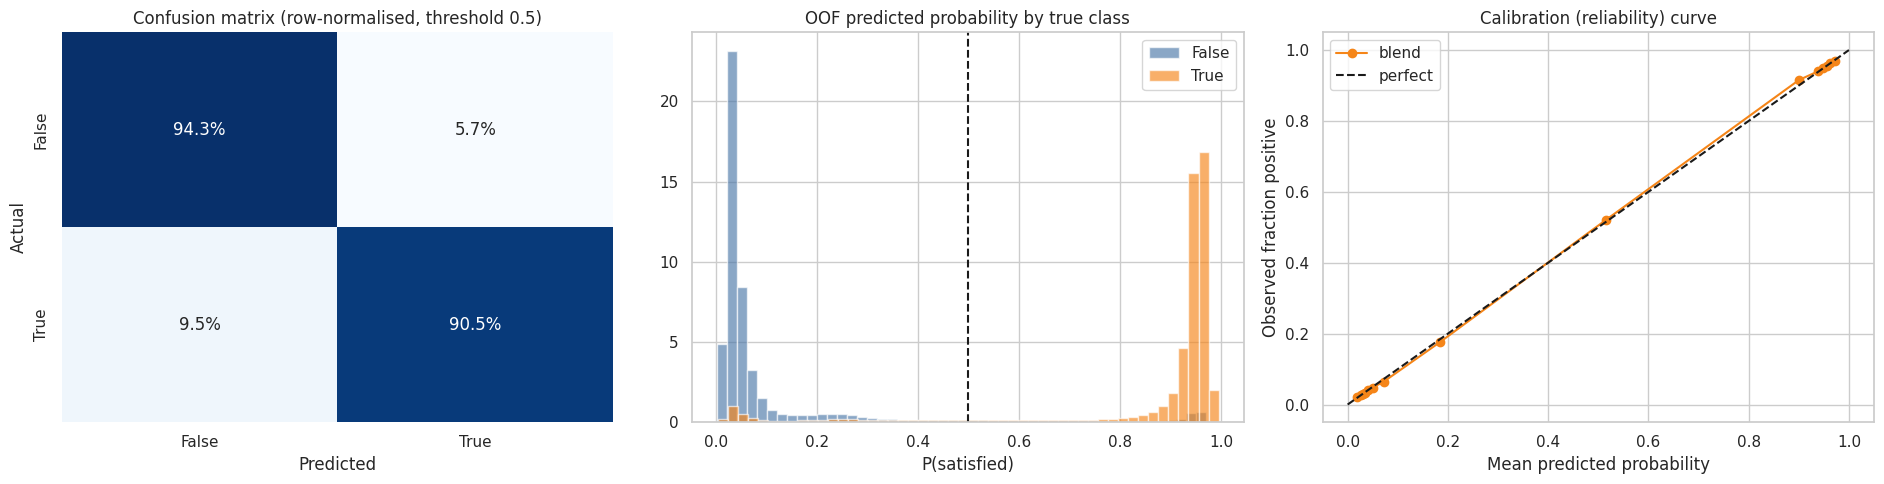

#### Key findings (auto-generated)
* At threshold 0.5: recall of *True* = **90.5%**, recall of *False* = **94.3%**.
* Calibration gap (mean |observed − predicted| over bins): **0.0035**.

In [17]:
if K == 2:
    p1 = oof_blend_eq[:, 1]
    fig, axes = plt.subplots(1, 3, figsize=(19, 5))
    # (a) confusion matrix at 0.5
    cmx = confusion_matrix(y, (p1 >= .5).astype(int), normalize='true')
    sns.heatmap(cmx, annot=True, fmt='.1%', cmap='Blues', cbar=False, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
    axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual'); axes[0].set_title('Confusion matrix (row-normalised, threshold 0.5)')
    # (b) probability histogram by true class
    axes[1].hist(p1[y == 0], bins=50, alpha=.65, color=C0, label=CLASS_NAMES[0], density=True)
    axes[1].hist(p1[y == 1], bins=50, alpha=.65, color=C1, label=CLASS_NAMES[1], density=True)
    axes[1].axvline(.5, color='k', ls='--'); axes[1].legend(); axes[1].set_title('OOF predicted probability by true class'); axes[1].set_xlabel('P(satisfied)')
    # (c) calibration
    fr, mp = calibration_curve(y, p1, n_bins=15, strategy='quantile')
    axes[2].plot(mp, fr, marker='o', color=C1, label='blend'); axes[2].plot([0, 1], [0, 1], 'k--', label='perfect')
    axes[2].set_xlabel('Mean predicted probability'); axes[2].set_ylabel('Observed fraction positive'); axes[2].legend(); axes[2].set_title('Calibration (reliability) curve')
    plt.tight_layout(); plt.show()
    tn, fp_, fn, tp = confusion_matrix(y, (p1 >= .5).astype(int)).ravel()
    say('#### Key findings (auto-generated)\n'
        f'* At threshold 0.5: recall of *{CLASS_NAMES[1]}* = **{tp/(tp+fn):.1%}**, recall of *{CLASS_NAMES[0]}* = **{tn/(tn+fp_):.1%}**.\n'
        f'* Calibration gap (mean |observed − predicted| over bins): **{np.mean(np.abs(fr - mp)):.4f}**.')

### Interpretation — errors, confidence and calibration
* **Confusion matrix:** the diagonal shows the share of each true class that is classified correctly. Compare the two recalls: similar values indicate the model is not biased toward the majority class; a large gap would suggest moving the decision threshold (in your earlier run the best threshold was 0.51, i.e. practically 0.5).
* **Probability histogram:** good models produce a *U-shape* — most passengers get probabilities near 0 or near 1 — with the two class colours separated. The overlap in the middle is the "hard" group of passengers the model cannot decide on; this region contains most of the errors.
* **Calibration curve:** points on the dashed diagonal mean the predicted probability equals the real frequency (e.g. of the passengers given 0.8, ~80 % are satisfied). If the metric is AUC, calibration does not matter (only ranking counts); if it were log-loss, a visible deviation would suggest a calibration step (Platt / isotonic).

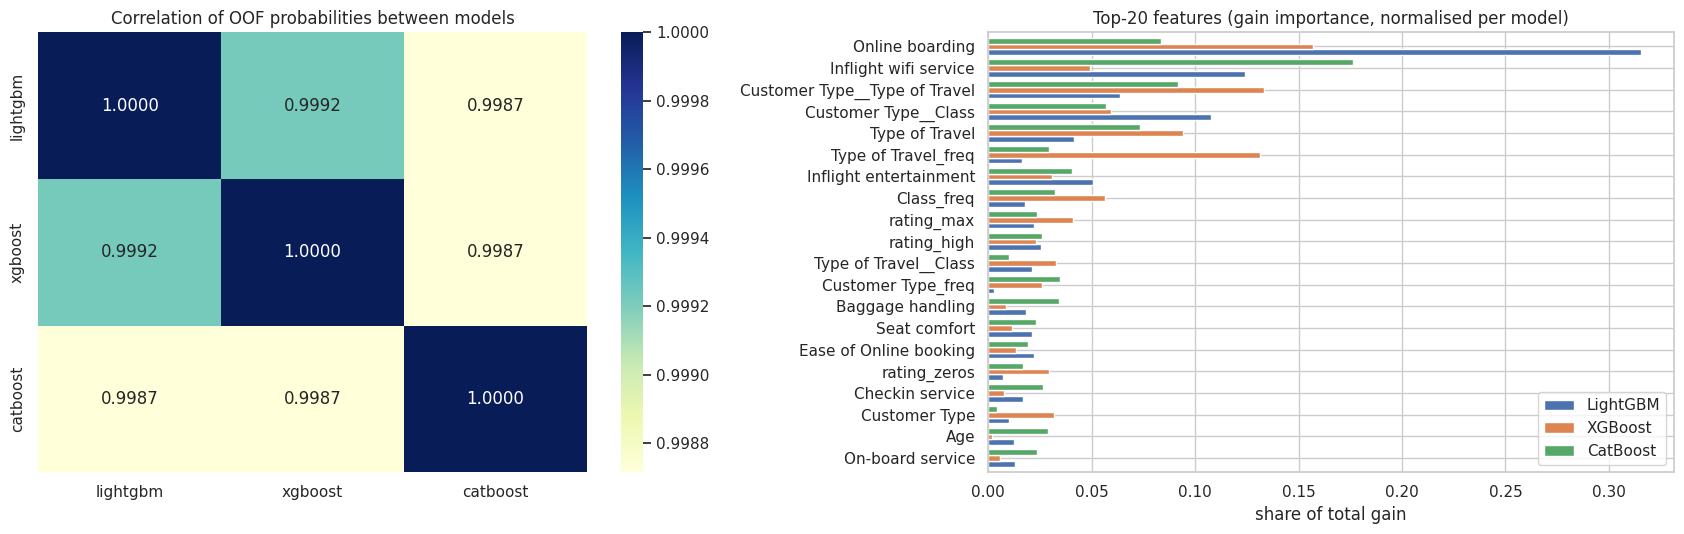

#### Key findings (auto-generated)
* Top-5 features by average importance: **Online boarding** (18.5%), **Inflight wifi service** (11.7%), **Customer Type__Type of Travel** (9.6%), **Customer Type__Class** (7.5%), **Type of Travel** (7.0%).
* Top-5 features hold **54%** of the total gain.
* Minimum pairwise correlation between model predictions: **0.9987**.

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
# (a) model agreement
P = pd.DataFrame({k: results[k][0][:, -1] for k in names})
if len(names) > 1:
    sns.heatmap(P.corr(), annot=True, fmt='.4f', cmap='YlGnBu', ax=axes[0]); axes[0].set_title('Correlation of OOF probabilities between models')
else:
    axes[0].axis('off'); axes[0].text(.5, .5, 'Only one model available', ha='center')
# (b) feature importance
if importances:
    imp = pd.DataFrame({k: pd.concat(v, axis=1).mean(axis=1) for k, v in importances.items()})
    imp['mean'] = imp.mean(axis=1)
    top = imp.sort_values('mean', ascending=False).head(20).iloc[::-1]
    top.drop(columns='mean').plot.barh(ax=axes[1], width=.8)
    axes[1].set_title('Top-20 features (gain importance, normalised per model)'); axes[1].set_xlabel('share of total gain')
else:
    axes[1].axis('off')
plt.tight_layout(); plt.show()
if importances:
    t5 = imp['mean'].sort_values(ascending=False).head(5)
    say('#### Key findings (auto-generated)\n* Top-5 features by average importance: ' + ', '.join(f'**{i}** ({v:.1%})' for i, v in t5.items())
        + f'.\n* Top-5 features hold **{t5.sum():.0%}** of the total gain.'
        + (f'\n* Minimum pairwise correlation between model predictions: **{P.corr().values.min():.4f}**.' if len(names) > 1 else ''))

### Interpretation — model agreement and feature importance
* **Agreement:** correlations very close to 1 between the models' predictions mean they learned essentially the same function. Your earlier run (AUCs within 0.0003 and a blend gain of only +0.0001) points the same way: blending these three GBDTs adds little, and "just add another GBDT" will not add much either.
* **Importance** (share of total split gain, averaged over folds and normalised per model so that libraries are comparable): the ranking tells you which information the models rely on. Compare the top bars with the ratings that were most discriminating in the EDA heatmap and with the engineered aggregates (`rating_mean`, `rating_sum`, `rating_low`) — features that rank high in both views are the ones the model depends on most.
* When the three models agree on the top features, that ranking is robust. Features at the bottom contribute almost nothing; they could be removed to speed up training, but keeping them costs little and did not hurt the CV score.
* Gain importance shows *how much a feature is used*, not the direction of the effect; for direction, use the rating heatmap in Section 2 (or SHAP).

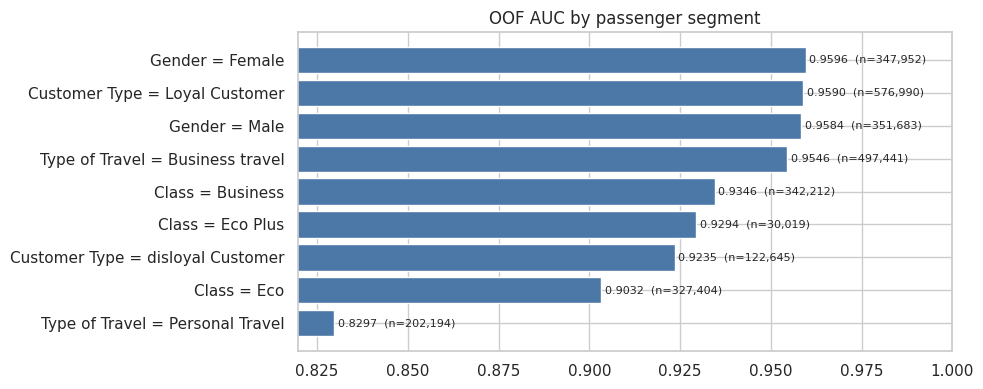

#### Key findings (auto-generated)
* Weakest segment: **Type of Travel = Personal Travel** (AUC 0.8297, accuracy 93.4%); strongest: **Gender = Female** (AUC 0.9596).
* Gap between best and worst segment: **0.1299** AUC.

In [19]:
# where is the model weaker?  AUC / accuracy of the (equal) blend per category level
if K == 2:
    rows = []
    for c in cat_eda:
        for lvl, idx in train.groupby(c).indices.items():
            if len(np.unique(y[idx])) == 2:
                rows.append({'feature': c, 'level': str(lvl), 'n': len(idx),
                             'AUC': roc_auc_score(y[idx], oof_blend_eq[idx, 1]),
                             'accuracy': accuracy_score(y[idx], oof_blend_eq[idx].argmax(1))})
    seg = pd.DataFrame(rows)
    seg['label'] = seg['feature'] + ' = ' + seg['level']
    seg = seg.sort_values('AUC')
    fig, ax = plt.subplots(figsize=(10, max(3, .45 * len(seg))))
    ax.barh(seg['label'], seg['AUC'], color=C0)
    ax.set_xlim(max(.8, seg['AUC'].min() - .01), 1); ax.set_title('OOF AUC by passenger segment')
    for i, (a_, n_) in enumerate(zip(seg['AUC'], seg['n'])): ax.text(a_ + .001, i, f'{a_:.4f}  (n={n_:,})', va='center', fontsize=8)
    plt.tight_layout(); plt.show()
    w, b_ = seg.iloc[0], seg.iloc[-1]
    say('#### Key findings (auto-generated)\n'
        f'* Weakest segment: **{w.label}** (AUC {w.AUC:.4f}, accuracy {w.accuracy:.1%}); strongest: **{b_.label}** (AUC {b_.AUC:.4f}).\n'
        f'* Gap between best and worst segment: **{b_.AUC - w.AUC:.4f}** AUC.')

### Interpretation — segment analysis
* The model is evaluated separately on each passenger group. A **small gap** means performance is uniform and the model is not failing for a particular type of passenger; a **large gap** would point to a segment that deserves its own features or a dedicated model.
* A segment with a lower AUC is one where satisfaction is less determined by the surveyed services (for example because it depends on factors that are not in the data).
* Because the AUC is measured within each segment, a lower value is not caused by differences in class balance between segments; it reflects genuinely harder-to-rank passengers.

## 6. Blend
Two options are compared on the OOF predictions: the **equal-weight mean** and **optimised weights** (non-negative, sum to 1, found with Nelder–Mead on OOF AUC). With only ≤ 3 weights and ~700k OOF rows, over-fitting the weights is a negligible risk. The better of the two is used for the submission.

,acc,logloss,auc,f1
lightgbm,0.92647,0.22662,0.95890,0.91612
xgboost,0.92630,0.22720,0.95874,0.91593
catboost,0.92642,0.22736,0.95863,0.91608
blend (equal),0.92651,0.22651,0.95900,0.91618
blend (optimised),0.92651,0.22651,0.95900,0.91618


weights  equal    : {'lightgbm': 0.333, 'xgboost': 0.333, 'catboost': 0.333}
weights  optimised: {'lightgbm': 0.333, 'xgboost': 0.333, 'catboost': 0.333}
USING: equal weights -> {'acc': 0.92651, 'logloss': 0.22651, 'auc': 0.959, 'f1': 0.91618}
Best threshold on OOF: 0.51  (acc 0.92654 vs 0.92651 at 0.5)


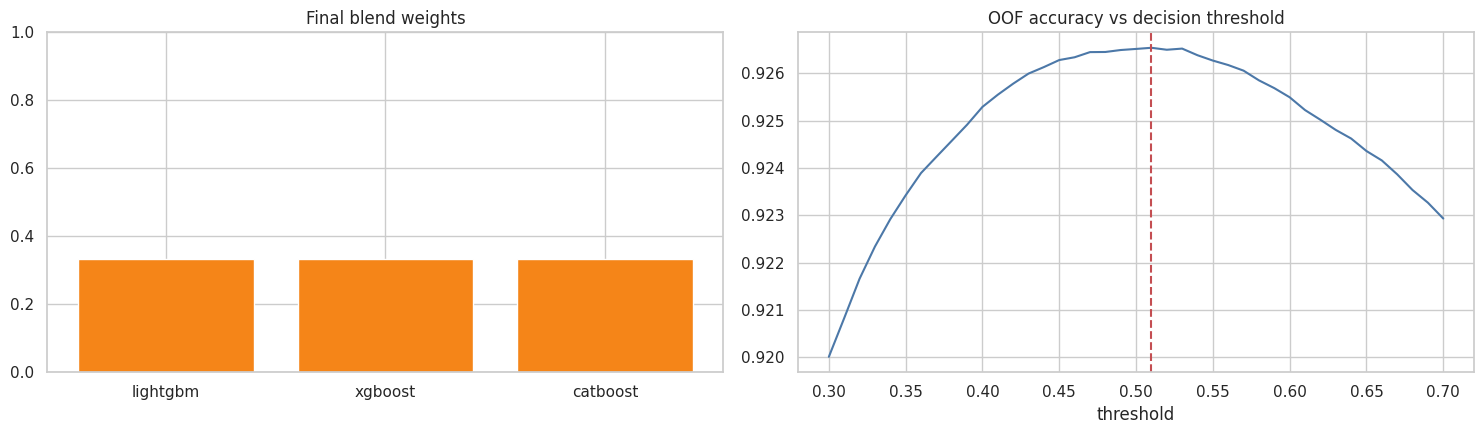

In [20]:
summary = pd.DataFrame({k: score(y, v[0]) for k, v in results.items()}).T
oof_list  = [results[k][0] for k in names]
pred_list = [results[k][1] for k in names]

def blend(ws, arrs): 
    ws = np.asarray(ws) / np.sum(ws)
    return sum(w * a for w, a in zip(ws, arrs))
def objective(z):                                   # softmax weights -> negative AUC (or logloss for multiclass)
    w = np.exp(z) / np.exp(z).sum(); b = blend(w, oof_list)
    return -roc_auc_score(y, b[:, 1]) if K == 2 else log_loss(y, b, labels=range(K))

w_eq = np.ones(len(names)) / len(names)
if len(names) > 1:
    res = minimize(objective, np.zeros(len(names)), method='Nelder-Mead', options={'maxiter': 80, 'xatol': 1e-3, 'fatol': 1e-7})
    w_opt = np.exp(res.x) / np.exp(res.x).sum()
else:
    w_opt = w_eq

oof_eq,  oof_opt  = blend(w_eq, oof_list),  blend(w_opt, oof_list)
s_eq, s_opt = score(y, oof_eq), score(y, oof_opt)
use_opt = (s_opt.get('auc', -s_opt['logloss']) > s_eq.get('auc', -s_eq['logloss']))
w_final = w_opt if use_opt else w_eq
oof_blend, pred_blend = blend(w_final, oof_list), blend(w_final, pred_list)

summary.loc['blend (equal)'] = s_eq
summary.loc['blend (optimised)'] = s_opt
display(summary)
print('weights  equal    :', {k: round(float(v), 3) for k, v in zip(names, w_eq)})
print('weights  optimised:', {k: round(float(v), 3) for k, v in zip(names, w_opt)})
print('USING:', 'optimised' if use_opt else 'equal', 'weights ->', score(y, oof_blend))

# binary: tune the decision threshold on OOF predictions (only used if the submission needs labels)
best_t = 0.5
if K == 2:
    ts = np.arange(0.30, 0.71, 0.01)
    accs = [accuracy_score(y, (oof_blend[:, 1] >= t).astype(int)) for t in ts]
    best_t = float(ts[int(np.argmax(accs))])
    print(f'Best threshold on OOF: {best_t:.2f}  (acc {max(accs):.5f} vs {accuracy_score(y, oof_blend.argmax(1)):.5f} at 0.5)')

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(names, w_final, color=C1); axes[0].set_title('Final blend weights'); axes[0].set_ylim(0, 1)
if K == 2:
    axes[1].plot(ts, accs, color=C0); axes[1].axvline(best_t, color='r', ls='--'); axes[1].set_title('OOF accuracy vs decision threshold'); axes[1].set_xlabel('threshold')
plt.tight_layout(); plt.show()

### Interpretation — blending
* The table compares every model with the two blends. In your earlier run the equal mean already gave AUC 0.95900 vs 0.95890 for the best single model; optimised weights can add at most a few 0.00001 because the models are nearly identical. The code keeps whichever is better on OOF, so the final blend is never worse than the equal-weight one.
* **Weights** near 1/3 each would mean the libraries are interchangeable; a large weight on one model means it carries most of the useful signal.
* **Threshold curve:** accuracy is almost flat around 0.5 (best threshold 0.51 improves accuracy by only ≈ 0.00003). The threshold is therefore irrelevant for the probability submission, and even for a label submission the default 0.5 is essentially optimal.

## 7. Submission

Submission mode: proba   (override with SUBMIT_MODE if the Evaluation tab says otherwise)
saved -> /kaggle/working/submission.csv (299844, 2) | all submission checks passed ✔


,id,satisfaction
0,699635,0.255388
1,699636,0.891598
2,699637,0.901863
3,699638,0.077237
4,699639,0.051237


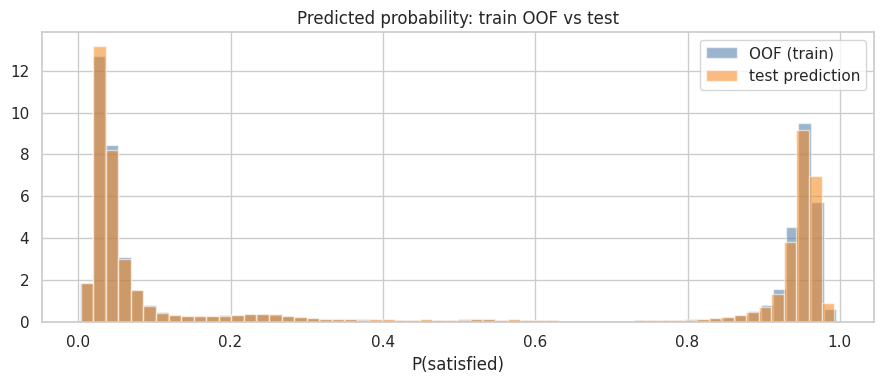

#### Key findings (auto-generated)
* Mean predicted probability — OOF: **0.4435**, test: **0.4436**, train positive rate: **0.4436**.

In [21]:
ids = test[ID_COL] if ID_COL in test.columns else sub[ID_COL]

mode = SUBMIT_MODE
if mode == 'auto':
    s = sub[TARGET]
    looks_like_proba = pd.api.types.is_float_dtype(s) and not set(s.unique()) <= {0.0, 1.0}
    mode = 'proba' if looks_like_proba else 'label'
print('Submission mode:', mode, '  (override with SUBMIT_MODE if the Evaluation tab says otherwise)')

if mode == 'proba':
    if K == 2:
        submission = pd.DataFrame({ID_COL: ids, TARGET: pred_blend[:, 1]})
    else:
        submission = pd.DataFrame(pred_blend, columns=[f'{TARGET}_{c}' for c in le.classes_])
        submission.insert(0, ID_COL, ids.values)
        if list(submission.columns) != list(sub.columns):
            submission.columns = sub.columns[:submission.shape[1]]
else:
    labels = (pred_blend[:, 1] >= best_t).astype(int) if K == 2 else pred_blend.argmax(1)
    submission = pd.DataFrame({ID_COL: ids, TARGET: le.inverse_transform(labels)})

# ---- final checks against the sample submission ----
assert len(submission) == len(sub), 'row count differs from sample_submission'
assert list(submission.columns) == list(sub.columns), 'columns differ from sample_submission'
assert (submission[ID_COL].values == sub[ID_COL].values).all(), 'ids / order differ from sample_submission'
assert submission.isna().sum().sum() == 0, 'NaNs in submission'
if mode == 'proba': assert submission[TARGET].between(0, 1).all(), 'probabilities outside [0, 1]'
out_path = os.path.join(OUT_DIR, 'submission.csv')
submission.to_csv(out_path, index=False)
print('saved ->', out_path, submission.shape, '| all submission checks passed ✔')
display(submission.head())

if mode == 'proba' and K == 2:
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(oof_blend[:, 1], bins=60, alpha=.55, density=True, color=C0, label='OOF (train)')
    ax.hist(pred_blend[:, 1], bins=60, alpha=.55, density=True, color=C1, label='test prediction')
    ax.set_title('Predicted probability: train OOF vs test'); ax.set_xlabel('P(satisfied)'); ax.legend()
    plt.tight_layout(); plt.show()
    say(f'#### Key findings (auto-generated)\n* Mean predicted probability — OOF: **{oof_blend[:,1].mean():.4f}**, test: **{pred_blend[:,1].mean():.4f}**, '
        f'train positive rate: **{ybin.mean():.4f}**.')

### Interpretation — final predictions
* The test-set probability histogram should look like the OOF histogram (same U-shape, same height of the two peaks). That is a direct confirmation that the test predictions come from the same distribution the models were validated on — no covariate shift, no bug in the test feature pipeline.
* The mean predicted probability on the test set should be close to the training positive rate (≈ 0.444). A big deviation would indicate shift or a feature-alignment problem; the asserts above already guarantee the alignment of ids, columns and row order with `sample_submission.csv`.
* Test predictions are an average over the 5 fold-models of each library (each trained on 80 % of the data), which is more stable than any single model.

### Next steps to improve the leaderboard score
1. **More information, not more tuning:** the models plateau at ≈ 0.959 AUC. In this Playground series the data are generated from the public *Airline Passenger Satisfaction* dataset; adding the original dataset as extra training rows (flag them with an `is_original` column) is the most common source of gains.
2. **Different model families** (a neural network on standardised features, or logistic regression on the rating aggregates) add the diversity that the three GBDTs lack.
3. **Multiple seeds / repeated CV** of the best model reduce variance at no risk.